# Coulomb potential

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Preamble

In [37]:
n = 1001
m = 9.1 *10**-31  # mass of electron in kg
h_bar = 1.054 * 10**-34  # Planck's constant in J*s
e = 1.6 * 10**-19  # elementary charge in C
r_min = 10**(-15)  # can't terminate at 0 cuz V \propto (1/r)
r_max = 10**(-9)
r = np.linspace(r_min, r_max, n)
delta_r = r[1] - r[0]
c = (h_bar**2) / (2*m *e*delta_r**2)
Z = 1  # Atomic number for hydrogen
# print(c)
k = 8.99 * 10**9  # Coulomb's constant (1/4 pi epsilon_0) in N*m^2/C^2

## Making Hamiltonian
$$ 
\hat H \psi= E \psi 
$$
with $\quad \psi(x,y,z) = R(r)\quad Y_l^m(\theta, \phi)\quad $ in spherical coordinates. 

In [38]:
v = -k*Z*e/r # in eV

pe = np.diag(v[1:-1])  # potential energy matrix

ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix

Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom

eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction

r_new = r[1:-1]  # new r values corresponding to the eigenvectors
print(eig_val[0:10], "eV")  # print the first 10 eigenvalues in eV

st = 3

[-13.55622583  -3.38856746  -1.28249708   0.78478463   3.75532965
   7.57878747  12.21766942  17.65173127  23.86888864  30.86142395] eV


## Finding bound states

In [ ]:
# bound_st = sum(eig_val < 0)  # count the number of negative eigenvalues (Bound states)
# print(bound_st)
# ordinary Coulomb potential has infinitely many

3


# Plot

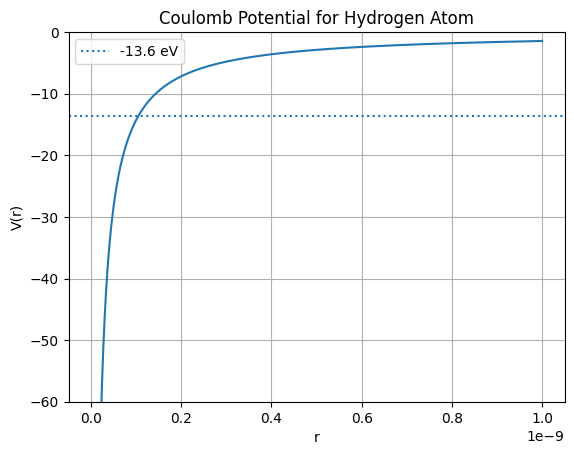

In [39]:
plt.plot(r_new, v[1:-1])
plt.title("Coulomb Potential for Hydrogen Atom")
plt.xlabel('r')
plt.ylabel("V(r)")
plt.axhline(y = -13.6, label = "-13.6 eV", ls=":")
plt.ylim(-60, 0)
plt.legend()
plt.grid()
plt.show()

In [46]:
# Everything is turning NEGATIVE, so we need to multiply by -1 to get the correct sign

eig_vec = -eig_vec  # eigenvectors corresponding to the first 3 eigenvalues
'''
plt.plot(r_new, v[1:-1])
plt.title("Potential Energy vs r")
plt.xlabel('r')
plt.ylabel("V(r)")
plt.grid()
plt.show()'''

'\nplt.plot(r_new, v[1:-1])\nplt.title("Potential Energy vs r")\nplt.xlabel(\'r\')\nplt.ylabel("V(r)")\nplt.grid()\nplt.show()'

### Normalise ; u(r)/r = R(r)
$ \int_{r min}^{r max} |u(r)|^2 dr = 1 $

In [ ]:
# print(r_new[0], r_new[-1])
u_r = np.zeros((n-2, st))  # initialize an array to store the normalized eigenvectors
print(np.sqrt(delta_r))
for i in range(st):
    print("\nBound state", i+1, ", eigenvalue:", eig_val[i])
    u_r2 = eig_vec[:,i]**2
    norm_square = np.trapezoid(u_r2, r_new)   
    print("Norm :", np.sqrt(norm_square))   
    u_r[:,i] = eig_vec[:,i] / np.sqrt(norm_square)  # normalize the eigenvectors    
print(u_r.shape)

9.999994999998751e-07

Bound state 1 , eigenvalue: -13.556225827143786
Norm : 9.99993051492341e-07

Bound state 2 , eigenvalue: -3.3885674593232418
Norm : 9.999986917851087e-07

Bound state 3 , eigenvalue: -1.2824970752729798
Norm : 9.999990909587916e-07
(999, 3)


### Plot u(r) vs r
Normalised

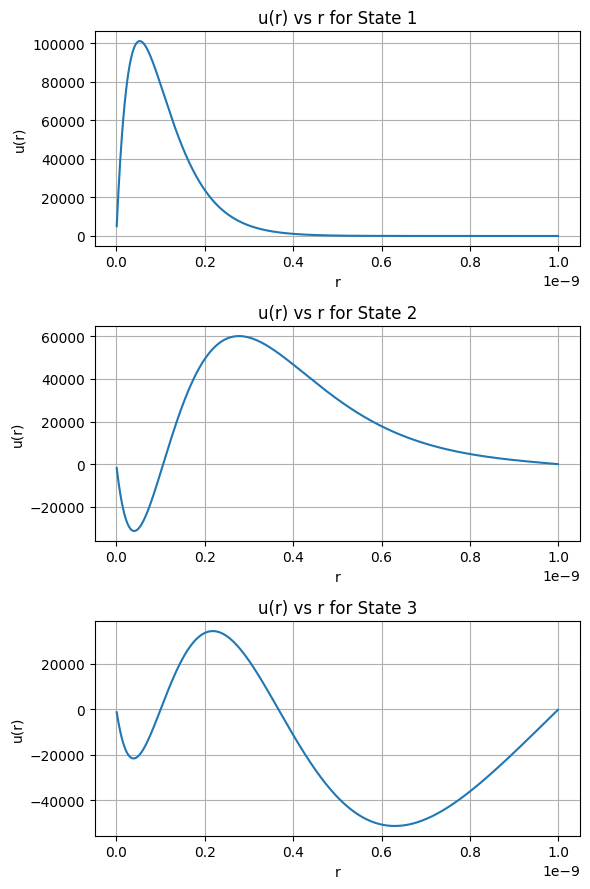

In [48]:
fig, axes = plt.subplots(st,1, figsize=(6, 3*st))

for i in range (st):
    axes[i].plot(r_new, u_r[:,i], label=f'State {i+1}')
    axes[i].set_title(f"u(r) vs r for State {i+1}")
    axes[i].set_xlabel('r')
    axes[i].set_ylabel("u(r)")
    axes[i].grid()

plt.tight_layout()
plt.show()

#### Probability density

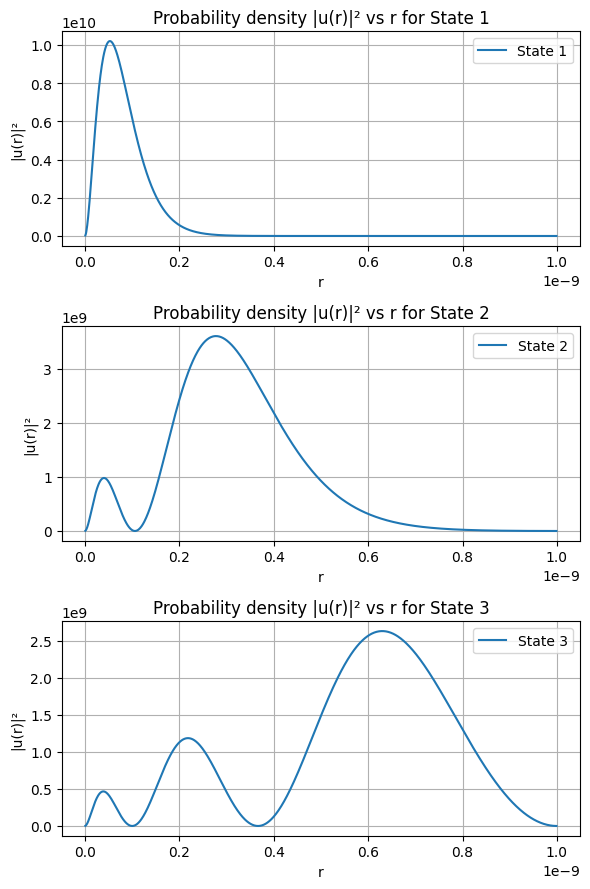

In [49]:
fig, axes = plt.subplots(st, 1,figsize=(6, 3*st),squeeze=False)
for i in range(st):
    axes[i, 0].plot(r_new, u_r[:, i]**2,label=f'State {i+1}')
    axes[i, 0].set_title(f"Probability density |u(r)|² vs r for State {i+1}")
    axes[i, 0].set_xlabel('r')
    axes[i, 0].set_ylabel('|u(r)|²')
    axes[i, 0].grid()
    axes[i, 0].legend()
plt.tight_layout()
plt.show()

(999, 3)


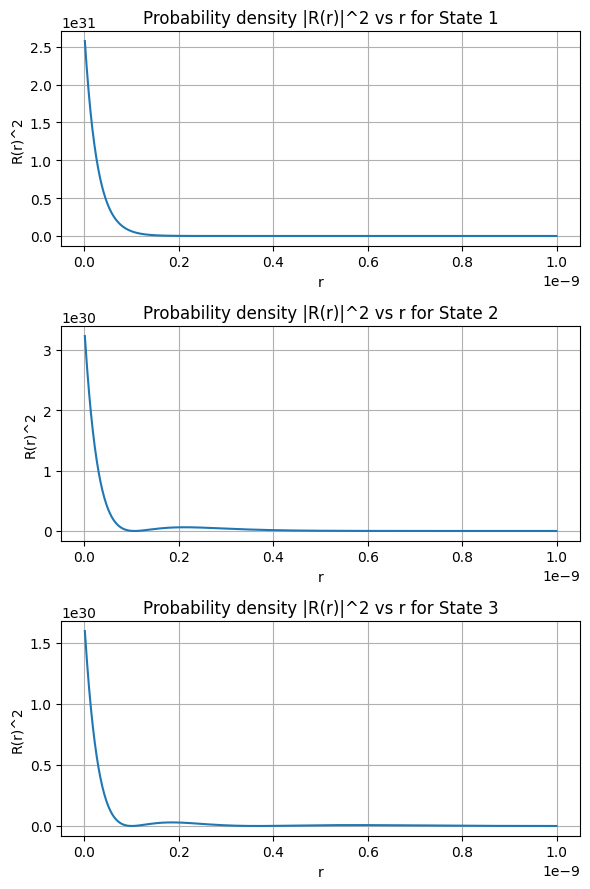

In [50]:
R_r = np.zeros((n-2, st)) 
print(R_r.shape)
for i in range(st):
    R_r[:,i] = u_r[:,i] / r_new  # calculate the radial wavefunction; R(r) = u(r)/r
fig, axes = plt.subplots(st, 1,figsize=(6, 3*st),squeeze=False)
for i in range (st):
    axes[i, 0].plot(r_new, R_r[:,i]**2, label=f'State {i+1}')
    axes[i, 0].set_title(f"Probability density |R(r)|^2 vs r for State {i+1}")
    axes[i, 0].set_xlabel('r')
    axes[i, 0].set_ylabel("R(r)^2")
    axes[i, 0].grid()
plt.tight_layout()
plt.show()

In [44]:
a = 0.529*10**(-10 ) # Bohr radius in m
R10_th = a**(-3/2)*(2 )* np.exp(-r_new/a)  # theoretical radial wavefunction for n=1, l=0
R20_th = a**(-3/2)*(1/(2*np.sqrt(2))) * (1 - r_new/(2*a)) * np.exp(-r_new/(2*a))  # theoretical radial wavefunction for n=2, l=0
R30_th = a**(-3/2)*(2/(3*np.sqrt(3))) * (1 - 2*r_new/(3*a) + (2/27)*(r_new/a)**2) * np.exp(-r_new/(3*a))  # theoretical radial wavefunction for n=3, l=0

### Compare R(r) obtained as the eigenvectors, and the plots of the theoretically well known analytic functions for R(r).

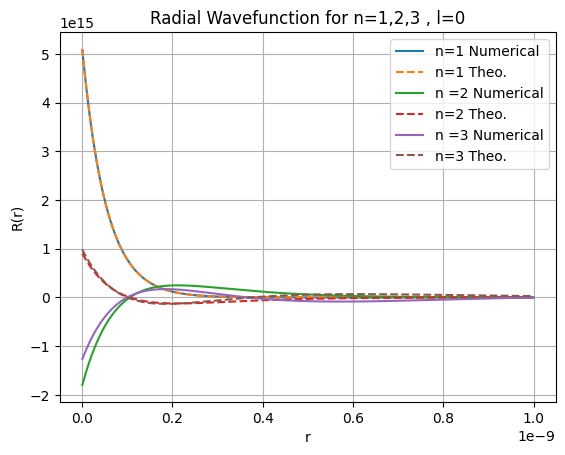

In [51]:

plt.plot(r_new, R_r[:,0], label='n=1 Numerical')
plt.plot(r_new, R10_th, label='n=1 Theo.',ls ='--')

plt.plot(r_new, R_r[:,1], label='n =2 Numerical')
plt.plot(r_new, R20_th, label='n=2 Theo.',ls ='--')

plt.plot(r_new, R_r[:,2], label='n =3 Numerical')
plt.plot(r_new, R30_th, label='n=3 Theo.',ls ='--')

plt.title("Radial Wavefunction for n=1,2,3 , l=0")
plt.xlabel('r')
plt.ylabel('R(r)')
plt.legend()
plt.grid()

plt.show()

In [52]:
print("Compare the eigenvalues obtained with the energies expected from the Bohr spectrum")
for i in range(st):
    print("\nState ", i+1)
    e_th = -13.6/(i+1)**2  # theoretical energy from Bohr spectrum
    print("E_numerical = ", eig_val[i], "(eigenvalue); E_Bohr (-13.6/n^2) = ", e_th, "eV")
    print("Percentage variation in eigenvalue from Bohr spectrum = ", (eig_val[i] - e_th)*100 / e_th, "%")
    
print("\nThe variation in the eigenvalues from the Bohr spectrum increases with increasing n (principal quantum number/state), as expected. \nThe numerical method is more accurate for lower energy states.")

Compare the eigenvalues obtained with the energies expected from the Bohr spectrum

State  1
E_numerical =  -13.556225827143786 (eigenvalue); E_Bohr (-13.6/n^2) =  -13.6 eV
Percentage variation in eigenvalue from Bohr spectrum =  -0.32186891806039536 %

State  2
E_numerical =  -3.3885674593232418 (eigenvalue); E_Bohr (-13.6/n^2) =  -3.4 eV
Percentage variation in eigenvalue from Bohr spectrum =  -0.3362511963752394 %

State  3
E_numerical =  -1.2824970752729798 (eigenvalue); E_Bohr (-13.6/n^2) =  -1.511111111111111 eV
Percentage variation in eigenvalue from Bohr spectrum =  -15.12887001869986 %

The variation in the eigenvalues from the Bohr spectrum increases with increasing n (principal quantum number/state), as expected. 
The numerical method is more accurate for lower energy states.


In [53]:
# 14 Oct
# Most probable r

# kron = np.zeros((bound_st,bound_st))

# for i in range(bound_st):
#     for j in range(bound_st):
#         t = np.dot(u_r[:,i],u_r[:,j])
#         kron[i,j] = t       
# print(kron)
prob_density = np.abs(u_r)**2
max_values = np.max(prob_density, axis=0)
max_indices = np.argmax(prob_density, axis=0)
most_probable_r = r_new[max_indices]
print("Maximum u(r)^2:", max_values)
print("Maximum indices:", max_indices)
print("Most probable r:", most_probable_r, "(m) for each state 1,2,3")


Maximum u(r)^2: [1.02043862e+10 3.60754569e+09 2.62983535e+09]
Maximum indices: [ 52 277 629]
Most probable r: [5.30009470e-11 2.78000722e-10 6.30000370e-10] (m) for each state 1,2,3


### The bound state solutions make up an orthonormal set
$ \int_{r_{min}}^{r_{max}} u^*_i u_j = 0 \quad$ for $ i \ne j$

In [ ]:
print("u_i * u_j = kronecker delta ij :--")
for i in range(st):
    for j in range(st):
        t = np.sum(np.conjugate(u_r[:,i])* (u_r[:,j]))    # or np.vdot()
        print(i+1, j+1, ":", t)
    print()   

print("Hence, the eigenvectors are orthonormal.")

u_i * u_j = kronecker delta ij :--
1 1 : 1000013897160.164
1 2 : 0.00037169456481933594
1 3 : 0.00013184547424316406

2 1 : 0.00037169456481933594
2 2 : 1000002616434.9171
2 3 : -0.000823974609375

3 1 : 0.00013184547424316406
3 2 : -0.000823974609375
3 3 : 1000001818084.896

Hence, the eigenvectors are orthonormal.


In [46]:
# 28 Oct 2026

psi = u_r.copy()  # psi = u(r) = r*R(r)
delx = delta_r
xnew = r_new
V = v[1:-1]  # potential energy values corresponding to the eigenvectors

exp_x = np.zeros(st)
exp_x2 = np.zeros(st)
exp_v = np.zeros(st)

# diff_psi = np.zeros((n-3, count))  # shape of diff_psi is (n-3, count)

exp_p = np.zeros(st)
exp_p2 = np.zeros(st)
exp_ke = np.zeros(st)

diff_psi = (psi[1:,:] - psi[:-1,:])/delx  # shape of diff_psi is (n-3, count)
xmid = (xnew[1:] + xnew[:-1])/2  # x_i = (x[i] + x[i+1])/2;  (everything except the first - everything except the last)/2
psi_mid = (psi[1:,:] + psi[:-1,:])/2
#print("this ", diff_psi.shape, psi_mid.shape, xmid.shape)

diff2_psi = (diff_psi[1:,:] - diff_psi[:-1,:])/delx  # shape of diff2_psi is (n-4, count)
psi_mid2 = psi[1:-1,:]  # shape of psi_mid2 is (n-4, count); exclude 1st & last point 
xmid2 = xnew[1:-1]

sigma_x = np.zeros(st)
sigma_p = np.zeros(st)
sigma_xp = np.zeros(st)
 # sigma_x * sigma_p >= h_bar/2 --> (sigma_x * sigma_p)*2/h_bar >= 1

print("Calculating expectation values for state:")
for i in range(st):
    print("\n",i+1,") ")
    yp = xnew* psi[:,i]**2
    # <x> = psi(x)^2 * x
    exp_x[i]= np.trapezoid(yp, xnew)
    
    # <x^2> = psi(x)^2 * x^2
    yp2 = (xnew* psi[:,i])**2
    exp_x2[i] = np.trapezoid(yp2, xnew)
    
    # <V> = psi(x)^2 * V(x)
    yp3 = V * psi[:,i]**2
    #print("yp3 shape: ", yp3.shape, "xnew shape: ", xnew.shape)
    exp_v[i] = np.trapezoid(yp3, xnew)
    
    print("<x> = ", exp_x[i])
    print("<x^2> = ", exp_x2[i]) 
    
    # <p> = -i*h_bar*(psi*(x) d(psi)/dx)
    yp4 = (psi_mid[:,i] * diff_psi[:,i])
    #print("yp4 shape: ", yp4.shape, "xmid shape: ", xmid.shape)
    exp_p[i] = (-1) * h_bar * np.trapezoid(yp4, xmid) 
    print("<p> = ", exp_p[i] * 1j)
    
    # <p^2> = -h_bar^2 *(psi*(x) d2(psi)/dx2)
    yp5 = psi_mid2[:,i]*diff2_psi[:,i]
    exp_p2[i]= np.trapezoid(yp5, xmid2) * (-1 * h_bar**2)
    print("<p^2> = ", exp_p2[i])
    
    # <k> = <p^2>/2m
    exp_ke[i] = exp_p2[i]/(2*m*e)
    print("<KE> = ", exp_ke[i])
    print("<PE> = ", exp_v[i], "= -2*<KE> =", -2*exp_ke[i]) 
    
    print("Total energy = <KE> + <V> = ", exp_ke[i] + exp_v[i],"= -<KE> =",-1*exp_ke[i], f" = eigenvalue {i+1} = ", eig_val[i], "eV")
    
    # Uncertainty in x = sqrt(<x^2> - <x>^2)
    var_x = exp_x2[i] - (exp_x[i]**2)
    sigma_x[i] = np.sqrt(var_x)
    var_p = exp_p2[i] - (exp_p[i]**2)
    sigma_p[i] = np.sqrt(var_p)
    
    sigma_xp[i] = sigma_x[i] * sigma_p[i]
    
print( "\nThe ratio of (sigma_x * sigma_p)/(h_bar/2) for each state:", (2/h_bar) * sigma_xp," (should be >= 1; Heisenberg uncertainty principle holds)")

Calculating expectation values for state:

 1 ) 
<x> =  7.957832994750854e-11
<x^2> =  8.44340369937359e-21
<p> =  3.297908996670562e-27j
<p^2> =  3.9257408902992265e-48
<KE> =  13.481253057346244
<PE> =  -27.090876556920847 = -2*<KE> = -26.962506114692488
Total energy = <KE> + <V> =  -13.609623499574603 = -<KE> = -13.481253057346244  = eigenvalue 1 =  -13.556225827143786 eV

 2 ) 
<x> =  3.1747996935457397e-10
<x^2> =  1.1734522184272612e-19
<p> =  4.131648280104551e-28j
<p^2> =  9.875107687747047e-49
<KE> =  3.3911770905724743
<PE> =  -6.786514895010843 = -2*<KE> = -6.782354181144949
Total energy = <KE> + <V> =  -3.3953378044383684 = -<KE> = -3.3911770905724743  = eigenvalue 2 =  -3.3885674593232418 eV

 3 ) 
<x> =  5.699380694434231e-10
<x^2> =  3.6673670654697606e-19
<p> =  1.9966919925685404e-28j
<p^2> =  7.772962283904441e-49
<KE> =  2.6692864985935576
<PE> =  -3.9551420804585065 = -2*<KE> = -5.338572997187115
Total energy = <KE> + <V> =  -1.2858555818649489 = -<KE> = -2.66928649

## Program 3: Sensitivity to Choice of Parameters
Check how do the number of bound states, as well as the accuracy of the respective energies (w.r.t. the energies expected from Bohr theory), change as we alter the choice of rmin and rmax.

In [48]:
n = 1001

## A: Vary $r_{min}$

In [49]:
r_min_values = [1e-14, 1e-15, 1e-16, 1e-17]
# n, m, h_bar, e, Z, k are already defined above
print("Exploring the effect of varying r_min on the number of bound states and eigenvalues:")
for r_min in r_min_values:
    r_max = 1e-9
    print("\nr_min =", r_min)
    r = np.linspace(r_min, r_max, n)
    delta_r = r[1] - r[0]
    c = (h_bar**2)/(2*m*e*delta_r**2)
    print("delta_r =", delta_r)
    print("c =", c)
    
    # HAMILTONIAN CONSTRUCTION
    v = -k*Z*e/r # in eV
    pe = np.diag(v[1:-1])  # potential energy matrix
    ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix
    Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom

    # np.linalg.eigh()
    eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction
    r_new = r[1:-1]  # new r values corresponding to the eigenvectors
    
    bound_st = sum(eig_val < 0)  # how many negative eigenvalues (Bound states)
    print("Number of bound states:", bound_st)
    
    # ENERGY CALCULATIONS 
    print("Comparing the eigenvalues obtained with the energies expected from the Bohr spectrum")
    for i in range(bound_st):
        print("\nState", i+1)
        print("Potential energy = ", np.diag(pe)[i])
        print("Kinetic energy = ", np.diag(ke)[i])
        print("Total energy = ", np.diag(Hamil)[i])
        e_th = -13.6/(i+1)**2  # theoretical energy from Bohr spectrum
        print("E_numerical = ", eig_val[i], "(eigenvalue); E_Bohr (-13.6/n^2) = ", e_th, "eV")
        print("Percentage variation = ", (eig_val[i] - e_th)*100 / e_th, "%")
    
    

Exploring the effect of varying r_min on the number of bound states and eigenvalues:

r_min = 1e-14
delta_r = 9.9999e-13
c = 38150.35091529117


Number of bound states: 3
Comparing the eigenvalues obtained with the energies expected from the Bohr spectrum

State 1
Potential energy =  -1424.1725165595699
Kinetic energy =  76300.70183058234
Total energy =  74876.52931402277
E_numerical =  -13.547218638032163 (eigenvalue); E_Bohr (-13.6/n^2) =  -13.6 eV
Percentage variation =  -0.3880982497635041 %

State 2
Potential energy =  -715.6290112339426
Kinetic energy =  76300.70183058234
Total energy =  75585.0728193484
E_numerical =  -3.3874383026747927 (eigenvalue); E_Bohr (-13.6/n^2) =  -3.4 eV
Percentage variation =  -0.3694616860355052 %

State 3
Potential energy =  -477.87851706163184
Kinetic energy =  76300.70183058234
Total energy =  75822.82331352071
E_numerical =  -1.2819381229113105 (eigenvalue); E_Bohr (-13.6/n^2) =  -1.511111111111111 eV
Percentage variation =  -15.165859513222097 %

r_min = 1e-15
delta_r = 9.999990000000002e-13
c = 38149.664211378156
Number of bound states: 3
Comparing the eigenvalues obtained with the ener

## B: Vary $r_{max}$

In [38]:
r_max_values = [2.5e-10, 5e-10, 1e-9, 2e-9, 5e-9] 
print("Exploring the effect of varying r_max on the number of bound states and eigenvalues:")
for r_max in r_max_values:
    r_min = 1e-14
    print("\nr_max =", r_max)
    r = np.linspace(r_min, r_max, n)
    delta_r = r[1] - r[0]
    c = (h_bar**2)/(2*m*e*delta_r**2)
    print("delta_r =", delta_r)
    print("c =", c)
    
    # HAMILTONIAN CONSTRUCTION
    v = -k*Z*e/r # in eV
    pe = np.diag(v[1:-1])  # potential energy matrix
    ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix
    Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom

    # np.linalg.eigh()
    eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction
    r_new = r[1:-1]  # new r values corresponding to the eigenvectors
    
    bound_st = sum(eig_val < 0)  # how many negative eigenvalues (Bound states)
    print("Number of bound states:", bound_st)
    
    # ENERGY CALCULATIONS 
    print("Comparing the eigenvalues obtained with the energies expected from the Bohr spectrum")
    for i in range(bound_st):
        print("\nState", i+1)
        print("Potential energy = ", np.diag(pe)[i])
        print("Kinetic energy = ", np.diag(ke)[i])
        print("Total energy = ", np.diag(Hamil)[i])
        e_th = -13.6/(i+1)**2  # theoretical energy from Bohr spectrum
        print("E_numerical = ", eig_val[i], "(eigenvalue); E_Bohr (-13.6/n^2) = ", e_th, "eV")
        print("Percentage variation = ", (eig_val[i] - e_th)*100 / e_th, "%")

Exploring the effect of varying r_max on the number of bound states and eigenvalues:

r_max = 2.5e-10
delta_r = 2.4999000000000003e-13
c = 610442.2409959785
Number of bound states: 1
Comparing the eigenvalues obtained with the energies expected from the Bohr spectrum

State 1
Potential energy =  -5532.520481556982
Kinetic energy =  1220884.481991957
Total energy =  1215351.9615104
E_numerical =  -13.395667032234151 (eigenvalue); E_Bohr (-13.6/n^2) =  -13.6 eV
Percentage variation =  -1.5024482923959468 %

r_max = 5e-10
delta_r = 4.999900000000001e-13
c = 152604.4557655404
Number of bound states: 2
Comparing the eigenvalues obtained with the energies expected from the Bohr spectrum

State 1
Potential energy =  -2820.447459754113
Kinetic energy =  305208.9115310808
Total energy =  302388.46407132666
E_numerical =  -13.547972627062414 (eigenvalue); E_Bohr (-13.6/n^2) =  -13.6 eV
Percentage variation =  -0.38255421277636414 %

State 2
Potential energy =  -1424.1866175567832
Kinetic energy 

In [47]:
n_values = [101, 201, 501, 1001, 2001, 4001]

for n in n_values:
    r_min = 1e-14
    r_max = 1e-9
    print("\nNumber of points n =", n)
    r = np.linspace(r_min, r_max, n)
    delta_r = r[1] - r[0]
    c = (h_bar**2)/(2*m*e*delta_r**2)
    print("delta_r =", delta_r)
    print("c =", c)
    
    # HAMILTONIAN CONSTRUCTION
    v = -k*Z*e/r # in eV
    pe = np.diag(v[1:-1])  # potential energy matrix
    ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix
    Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom

    # np.linalg.eigh()
    eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction
    r_new = r[1:-1]  # new r values corresponding to the eigenvectors
    
    bound_st = sum(eig_val < 0)  # how many negative eigenvalues (Bound states)
    print("Number of bound states:", bound_st)


Number of points n = 101
delta_r = 9.9999e-12
c = 381.5035091529117
Number of bound states: 3

Number of points n = 201
delta_r = 4.99995e-12
c = 1526.0140366116468
Number of bound states: 3

Number of points n = 501
delta_r = 1.99998e-12
c = 9537.587728822793
Number of bound states: 3

Number of points n = 1001
delta_r = 9.9999e-13
c = 38150.35091529117
Number of bound states: 3

Number of points n = 2001
delta_r = 4.99995e-13
c = 152601.4036611647
Number of bound states: 3

Number of points n = 4001
delta_r = 2.499975e-13
c = 610405.6146446588
Number of bound states: 3
